<a href="https://colab.research.google.com/github/The-Harsh-07/ML-CIE-1-Activity-AD3121/blob/main/ML_CIE_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Wine Quality - Comprehensive Data Exploration and Cleaning Pipeline

This notebook demonstrates a structured approach to selecting, inspecting, cleaning, visualising, scaling, and exporting a tabular dataset for machine learning workflows.

### Step 1: Loading and Inspecting the Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df = pd.read_csv(url, sep=';')

print("--- First 5 Rows ---")
display(df.head())
print("\n--- Last 5 Rows ---")
display(df.tail())

--- First 5 Rows ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



--- Last 5 Rows ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


### Steps 2 & 3: Descriptive Statistics & Missing Values Analysis

In [ ]:
print("--- Data Types and Missing Values info ---")
df.info()
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Descriptive Statistics ---")
display(df.describe())

--- Data Types and Missing Values info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

--- Missing Values Count ---
fixed acidity           0
volatile acidity        0
c

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [ ]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows in the original dataset: {duplicate_count}")

df.drop_duplicates(inplace=True)
print(f"Number of duplicate rows after dropping: {df.duplicated().sum()}")

Number of duplicate rows in the original dataset: 240
Number of duplicate rows after dropping: 0


### Step 4: Exploratory Data Analysis & Visualizations

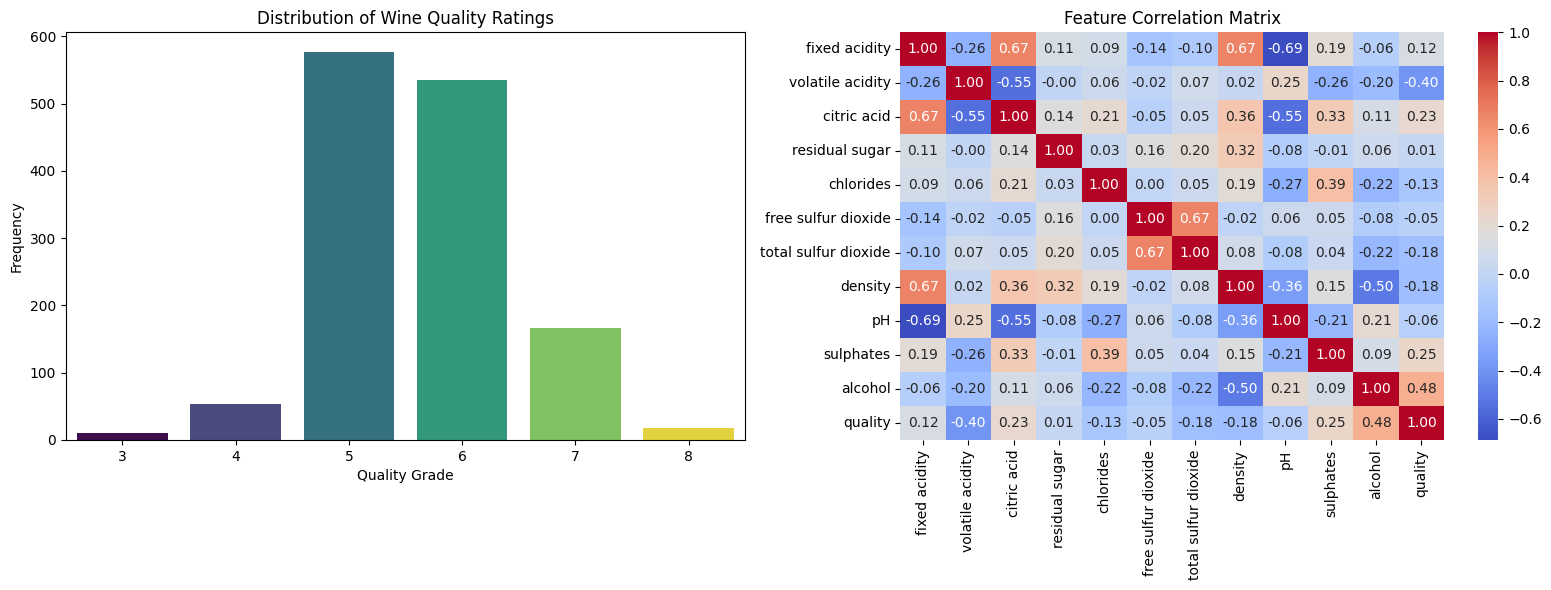

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=df, x='quality', ax=axes[0], palette='viridis', hue='quality', legend=False)
axes[0].set_title('Distribution of Wine Quality Ratings')
axes[0].set_xlabel('Quality Grade')
axes[0].set_ylabel('Frequency')

corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], cbar=True)
axes[1].set_title('Feature Correlation Matrix')

plt.tight_layout()
plt.show()

### Step 5: Handling Outliers

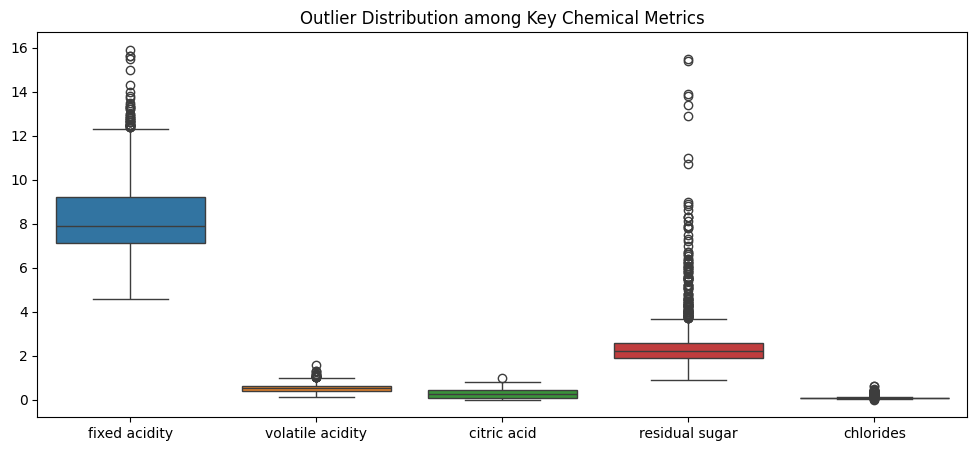

Original dataset shape: (1359, 12)
Cleaned dataset shape (extreme outliers removed): (1220, 12)


In [ ]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides']])
plt.title('Outlier Distribution among Key Chemical Metrics')
plt.show()

Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

df_cleaned = df[~((df < (Q1 - 3 * IQR)) | (df > (Q3 + 3 * IQR))).any(axis=1)]
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape (extreme outliers removed): {df_cleaned.shape}")

### Steps 8 & 9: Scaling & Saving Clean Data

In [ ]:
features = df_cleaned.drop(columns=['quality'])
target = df_cleaned['quality']

scaler = StandardScaler()
scaled_vals = scaler.fit_transform(features)

df_prepared = pd.DataFrame(scaled_vals, columns=features.columns, index=df_cleaned.index)
df_prepared['quality'] = target

output_file = 'red_wine_quality_prepared.csv'
df_prepared.to_csv(output_file, index=False)
print(f"\nPrepared dataset saved successfully to: '{output_file}'")
print(f"Final Prepared shape: {df_prepared.shape}")


Prepared dataset saved successfully to: 'red_wine_quality_prepared.csv'
Final Prepared shape: (1220, 12)
